<center><h1>Raza_MohammadHasnain_HW7_Extra</h1></center>
<br>
<center><font size="4">Extra Practice: ISLR 12.6.1 and 12.6.3 to 12.6.13</font></center>

**Name:** Mohammad Hasnain Raza  
**GitHub Username:** hasnainrazaa03  
**USC ID:** 1259246355

Package imports

In [1]:
# all imports and dependencies
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.stats import ttest_ind
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# seed used for the random labels, the simulations and k-means
SEED = 42

# relative paths
ARRESTS_PATH = "../data/islr/USArrests.csv"
BOSTON_PATH = "../data/islr/Boston.csv"
GENES_PATH = "../data/islr/Ch12Ex13.csv"

## 4.1. ISLR 12.6.1 - Extra Practice

*This problem involves the K-means clustering algorithm.*

**(a)** *Prove (12.18):*
$$\frac{1}{|C_k|}\sum_{i, i' \in C_k}\sum_{j=1}^p (x_{ij} - x_{i'j})^2 = 2\sum_{i \in C_k}\sum_{j=1}^p (x_{ij} - \bar x_{kj})^2, \qquad \bar x_{kj} = \frac{1}{|C_k|}\sum_{i \in C_k} x_{ij}.$$
**Answer.** Fix a feature $j$ and write $a_i = x_{ij} - \bar x_{kj}$, so that $x_{ij} - x_{i'j} = a_i - a_{i'}$ and $\sum_{i \in C_k} a_i = 0$. Then
$$\sum_{i, i' \in C_k}(a_i - a_{i'})^2 = \sum_{i, i'} a_i^2 + \sum_{i, i'} a_{i'}^2 - 2\sum_{i, i'} a_i a_{i'} = 2|C_k|\sum_{i \in C_k} a_i^2 - 2\Big(\sum_i a_i\Big)\Big(\sum_{i'} a_{i'}\Big) = 2|C_k|\sum_{i \in C_k} a_i^2,$$
because the last term is $-2 \cdot 0 \cdot 0$. Dividing by $|C_k|$ and summing over $j = 1, \dots, p$ gives (12.18). The code below checks it on a random cluster.

**(b)** *On the basis of this identity, argue that the K-means clustering algorithm (Algorithm 12.2) decreases the objective (12.17) at each iteration.* **Answer.** By (12.18) the objective (12.17) is
$$W = 2\sum_{k=1}^K \sum_{i \in C_k}\|x_i - \bar x_k\|^2 = 2\min_{\mu_1, \dots, \mu_K}\sum_{k=1}^K \sum_{i \in C_k}\|x_i - \mu_k\|^2,$$
since for a fixed cluster the mean is the point with the smallest sum of squared distances to its members. Step 2(a) sets every center to its cluster mean, which is that minimizer for the current clusters. Step 2(b) moves every observation to its closest center, which with the centers fixed can only lower (or keep) each $\|x_i - \mu_{C(i)}\|^2$, and recomputing the means in the next step 2(a) lowers the sum again (or keeps it). So the objective never goes up. There are only finitely many ways to split $n$ observations into $K$ clusters, so the algorithm stops changing after finitely many iterations, at a local (not necessarily global) optimum.

In [2]:
# numerical check of (12.18) on a random cluster
rng = np.random.default_rng(SEED)
cluster = rng.normal(size=(7, 3))
left = ((cluster[:, None, :] - cluster[None, :, :]) ** 2).sum() / len(cluster)
right = 2 * ((cluster - cluster.mean(axis=0)) ** 2).sum()
print(f"left side = {left:.6f}, right side = {right:.6f}")

left side = 28.443305, right side = 28.443305


## 4.2. ISLR 12.6.3 - Extra Practice

*Perform K-means clustering manually, with $K = 2$, on $n = 6$ observations with $p = 2$ features: obs. 1 (1, 4), 2 (1, 3), 3 (0, 4), 4 (5, 1), 5 (6, 2) and 6 (4, 0), written as $(X_1, X_2)$. (a) Plot the observations. (b) Randomly assign a cluster label to each observation and report the labels. (c) Compute the centroid for each cluster. (d) Assign each observation to the centroid to which it is closest, in terms of Euclidean distance, and report the labels. (e) Repeat (c) and (d) until the answers obtained stop changing. (f) In your plot from (a), color the observations according to the cluster labels obtained.*

(b) random labels: [1 2 2 1 1 2]
step 1: centroids [[4.0, 2.333], [1.667, 2.333]] -> labels [2 2 2 1 1 1]
step 2: centroids [[5.0, 1.0], [0.667, 3.667]] -> labels [2 2 2 1 1 1]


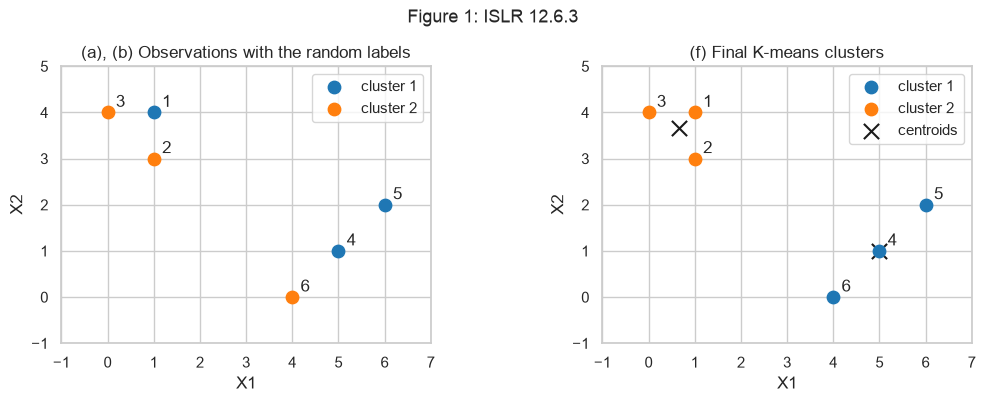

In [3]:
SIX_OBS = np.array([[1, 4], [1, 3], [0, 4], [5, 1], [6, 2], [4, 0]])

# (b) random labels, drawn again if one cluster is empty
rng = np.random.default_rng(SEED)
cluster_labels = rng.choice([1, 2], size=len(SIX_OBS))
while len(np.unique(cluster_labels)) < 2:
    cluster_labels = rng.choice([1, 2], size=len(SIX_OBS))
start_labels = cluster_labels.copy()
print("(b) random labels:", cluster_labels)

# (c) to (e) alternate between centroids and nearest-centroid labels
for step in range(1, 11):
    centroids = np.array([SIX_OBS[cluster_labels == c].mean(axis=0) for c in [1, 2]])
    distances = np.linalg.norm(SIX_OBS[:, None, :] - centroids[None, :, :], axis=2)
    new_labels = distances.argmin(axis=1) + 1
    print(f"step {step}: centroids {centroids.round(3).tolist()} -> labels {new_labels}")
    if np.array_equal(new_labels, cluster_labels):
        break
    cluster_labels = new_labels

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labels, title in [(axes[0], start_labels, "(a), (b) Observations with the random labels"), (axes[1], cluster_labels, "(f) Final K-means clusters")]:
    for c, color in [(1, "tab:blue"), (2, "tab:orange")]:
        ax.scatter(*SIX_OBS[labels == c].T, s=80, c=color, label=f"cluster {c}", zorder=3)
    for i, (x1, x2) in enumerate(SIX_OBS, start=1):
        ax.annotate(str(i), (x1, x2), textcoords="offset points", xytext=(6, 4))
    ax.set(xlim=(-1, 7), ylim=(-1, 5), xlabel="X1", ylabel="X2", title=title, aspect="equal")
axes[1].scatter(*centroids.T, marker="x", s=120, c="k", label="centroids")
for ax in axes:
    ax.legend(loc="upper right")
fig.suptitle("Figure 1: ISLR 12.6.3", fontsize=13)
plt.tight_layout()
plt.show()

**Answer.**

- **(a), (b)** The observations form two groups, $\{1, 2, 3\}$ at the top left and $\{4, 5, 6\}$ at the bottom right (Figure 1, left, colored by the random labels printed above).
- **(c), (d)** Each step prints the two centroids (the means of the current clusters) and the new labels from the nearest centroid.
- **(e)** The labels stop changing after the second step. The final clusters are **$\{1, 2, 3\}$ with centroid $(2/3, 11/3) \approx (0.67, 3.67)$ and $\{4, 5, 6\}$ with centroid $(5, 1)$** (the cluster numbers themselves are arbitrary).
- **(f)** Figure 1 (right) colors the observations by their final cluster. K-means finds the two groups that are visible in the plot.

## 4.3. ISLR 12.6.4 - Extra Practice

*Suppose that for a particular data set, we perform hierarchical clustering using single linkage and using complete linkage. We obtain two dendrograms.*

**(a)** *At a certain point on the single linkage dendrogram, the clusters $\{1, 2, 3\}$ and $\{4, 5\}$ fuse. On the complete linkage dendrogram, the clusters $\{1, 2, 3\}$ and $\{4, 5\}$ also fuse at a certain point. Which fusion will occur higher on the tree, or will they fuse at the same height, or is there not enough information to tell?* **Answer. Not enough information to tell for sure.** Both fusions join the same two clusters, so both heights come from the same six dissimilarities $d(i, i')$ with $i \in \{1, 2, 3\}$ and $i' \in \{4, 5\}$. Single linkage uses their minimum and complete linkage their maximum, so the complete linkage fusion is **at least as high**. It is strictly higher unless all six dissimilarities are equal, and then the two fusions are at the same height.

**(b)** *At a certain point on the single linkage dendrogram, the clusters $\{5\}$ and $\{6\}$ fuse. On the complete linkage dendrogram, the clusters $\{5\}$ and $\{6\}$ also fuse at a certain point. Which fusion will occur higher on the tree, or will they fuse at the same height, or is there not enough information to tell?* **Answer. They fuse at the same height.** Each cluster has one observation, so there is only one dissimilarity, $d(5, 6)$. Its minimum and maximum are the same number, so both dendrograms fuse $\{5\}$ and $\{6\}$ at height $d(5, 6)$.

## 4.4. ISLR 12.6.5 - Extra Practice

*In words, describe the results that you would expect if you performed K-means clustering of the eight shoppers in Figure 12.16, on the basis of their sock and computer purchases, with $K = 2$. Give three answers, one for each of the variable scalings displayed. Explain.*

**Answer.** K-means uses Euclidean distance, so the variable with the largest spread decides the clusters. In Figure 12.16 the eight shoppers bought between 5 and 11 pairs of socks, and the last four bought one computer each.

- **Raw counts (left panel).** Sock counts vary by several pairs while computers only go from 0 to 1, so socks drive the distances. The shoppers would be **split by how many socks they bought**, and buying a computer would barely matter.
- **Scaled by standard deviation (center panel).** Both variables now count about equally, and the computer variable takes only two values that are far apart after scaling. The clusters would most likely be **computer buyers and non-buyers**.
- **Dollars spent (right panel).** A computer costs far more than a pair of socks, so computer spending drives the distances, and the shoppers would be **split into those who bought a computer and those who did not**.

So the scaling of the variables can change the clusters completely, and it should match what matters for the problem. The code below checks the three answers on the values read off the figure.

In [4]:
# purchases of the eight shoppers, read off Figure 12.16 (left panel)
socks = np.array([8, 11, 7, 6, 5, 6, 7, 8])
computers = np.array([0, 0, 0, 0, 1, 1, 1, 1])
raw_counts = np.column_stack([socks, computers])

# center panel: each variable divided by its standard deviation
# right panel: dollars spent, assuming $3 per pair of socks and $1800 per computer
scalings = {"raw counts": raw_counts, "scaled by std": raw_counts / raw_counts.std(axis=0, ddof=1), "dollars": raw_counts * [3, 1800]}
for name, data in scalings.items():
    labels = KMeans(n_clusters=2, n_init=50, random_state=SEED).fit_predict(data)
    groups = [[int(i) + 1 for i in np.where(labels == c)[0]] for c in np.unique(labels)]
    print(f"{name:<14} clusters (shoppers 1 to 8): {groups}")

raw counts     clusters (shoppers 1 to 8): [[1, 3, 4, 5, 6, 7, 8], [2]]
scaled by std  clusters (shoppers 1 to 8): [[1, 2, 3, 4], [5, 6, 7, 8]]
dollars        clusters (shoppers 1 to 8): [[1, 2, 3, 4], [5, 6, 7, 8]]


**Answer.** The K-means fits agree. On the raw counts shopper 2, who bought 11 pairs of socks, ends up alone and the computer buyers are mixed with the others, so only the sock counts matter. After scaling and in dollars the two clusters are exactly the non-buyers (shoppers 1 to 4) and the computer buyers (shoppers 5 to 8).

## 4.5. ISLR 12.6.6 - Extra Practice

*We saw in Section 12.2.2 that the principal component loading and score vectors provide an approximation to a matrix, in the sense of (12.5). Specifically, the principal component score and loading vectors solve the optimization problem given in (12.6). Now, suppose that the M principal component score vectors $z_{im}$, $m = 1, \dots, M$, are known. Using (12.6), explain that each of the first M principal component loading vectors $\phi_{jm}$, $m = 1, \dots, M$, can be obtained by performing $p$ separate least squares linear regressions. In each regression, the principal component score vectors are the predictors, and one of the features of the data matrix is the response.*

**Answer.** Problem (12.6) is
$$\min_{A, B}\ \sum_{j=1}^p \sum_{i=1}^n \Big(x_{ij} - \sum_{m=1}^M a_{im} b_{jm}\Big)^2,$$
and its solution is $a_{im} = z_{im}$ (scores) and $b_{jm} = \phi_{jm}$ (loadings). If the scores are known and held fixed, the objective is a sum of $p$ terms, and the $j$th term only involves $b_{j1}, \dots, b_{jM}$:
$$\sum_{j=1}^p \underbrace{\sum_{i=1}^n \Big(x_{ij} - \sum_{m=1}^M z_{im} b_{jm}\Big)^2}_{\text{depends only on } b_{j1}, \dots, b_{jM}}.$$
So each term can be minimized on its own. The $j$th term is exactly the residual sum of squares of a linear regression (with no intercept, since the columns are centered) of the response $x_{1j}, \dots, x_{nj}$ on the predictors $z_1, \dots, z_M$, and its least squares coefficients are the loadings $\phi_{j1}, \dots, \phi_{jM}$. Doing this for $j = 1, \dots, p$ gives all $M$ loading vectors from $p$ separate regressions. The score vectors are orthogonal, so each coefficient is simply $\phi_{jm} = \sum_i z_{im}x_{ij} / \sum_i z_{im}^2$. The code below checks this on a small random data set.

In [5]:
# check: regress each centered column on the first M score vectors
rng = np.random.default_rng(SEED)
data = rng.normal(size=(30, 5)) @ rng.normal(size=(5, 5))
data = data - data.mean(axis=0)
M = 2
_, _, vt = np.linalg.svd(data, full_matrices=False)
loadings = vt[:M].T
scores = data @ loadings
regression_loadings = np.linalg.lstsq(scores, data, rcond=None)[0].T
print("loadings from PCA:\n", loadings.round(4))
print("loadings from 5 least squares regressions:\n", regression_loadings.round(4))
print("largest difference:", np.abs(loadings - regression_loadings).max())

loadings from PCA:
 [[ 0.4239  0.2412]
 [-0.2913  0.1956]
 [-0.8093 -0.135 ]
 [ 0.2836 -0.5195]
 [ 0.0092 -0.7845]]
loadings from 5 least squares regressions:
 [[ 0.4239  0.2412]
 [-0.2913  0.1956]
 [-0.8093 -0.135 ]
 [ 0.2836 -0.5195]
 [ 0.0092 -0.7845]]
largest difference: 3.5908775952719907e-16


## 4.6. ISLR 12.6.7 - Extra Practice

*Correlation-based distance and Euclidean distance are almost equivalent: if each observation has been centered to have mean zero and standard deviation one, and $r_{ij}$ is the correlation between the $i$th and $j$th observations, then $1 - r_{ij}$ is proportional to the squared Euclidean distance between them. On the `USArrests` data, show that this proportionality holds.*

(50, 4) ['Murder', 'Assault', 'UrbanPop', 'Rape']
1225 pairs of states, squared distance / (1 - r): min = 6.000000, max = 6.000000
without centering the states: ratio from 0.21 to 11908.55
  and the correlation of the two distances is 0.290


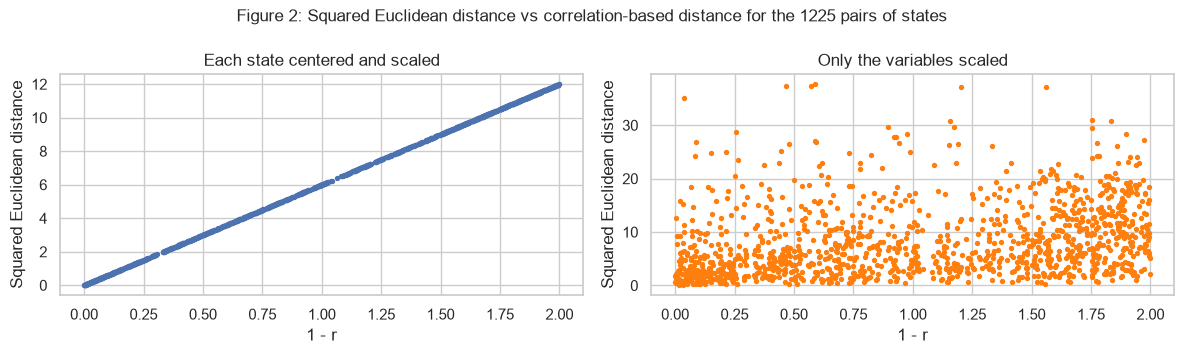

In [6]:
arrests_df = pd.read_csv(ARRESTS_PATH, index_col=0)
print(arrests_df.shape, list(arrests_df.columns))

# scale the variables first, then center each state (row) to mean 0 and standard deviation 1
scaled_arrests = StandardScaler().fit_transform(arrests_df)
state_rows = (scaled_arrests - scaled_arrests.mean(axis=1, keepdims=True)) / scaled_arrests.std(axis=1, ddof=1, keepdims=True)

def distance_and_correlation(rows):
    # squared Euclidean distance and 1 - r for every pair of states
    pairs = np.triu_indices(len(rows), k=1)
    squared_dist = ((rows[:, None, :] - rows[None, :, :]) ** 2).sum(axis=2)[pairs]
    return squared_dist, 1 - np.corrcoef(rows)[pairs]

squared_dist, one_minus_r = distance_and_correlation(state_rows)
ratio = squared_dist / one_minus_r
print(f"{len(ratio)} pairs of states, squared distance / (1 - r): min = {ratio.min():.6f}, max = {ratio.max():.6f}")

# for comparison: variables scaled, but the states not centered
cols_dist, cols_r = distance_and_correlation(scaled_arrests)
print(f"without centering the states: ratio from {(cols_dist / cols_r).min():.2f} to {(cols_dist / cols_r).max():.2f}")
print(f"  and the correlation of the two distances is {np.corrcoef(cols_dist, cols_r)[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(one_minus_r, squared_dist, s=8)
axes[0].set(xlabel="1 - r", ylabel="Squared Euclidean distance", title="Each state centered and scaled")
axes[1].scatter(cols_r, cols_dist, s=8, color="tab:orange")
axes[1].set(xlabel="1 - r", ylabel="Squared Euclidean distance", title="Only the variables scaled")
fig.suptitle("Figure 2: Squared Euclidean distance vs correlation-based distance for the 1225 pairs of states", fontsize=12)
plt.tight_layout()
plt.show()

**Answer.** For all 1225 pairs of states the ratio of the squared Euclidean distance to $1 - r_{ij}$ is **exactly 6** (Figure 2, left). This follows from the definitions. Each state's row has $p = 4$ values with mean 0 and standard deviation 1, so $\sum_k x_{ik}^2 = p - 1$ and $r_{ij} = \sum_k x_{ik}x_{jk}/(p - 1)$. Then
$$\|x_i - x_j\|^2 = \sum_k x_{ik}^2 + \sum_k x_{jk}^2 - 2\sum_k x_{ik}x_{jk} = 2(p - 1) - 2(p - 1)r_{ij} = 2(p - 1)(1 - r_{ij}) = 6(1 - r_{ij}).$$
The variables were scaled first so that Assault (the largest numbers) does not set the pattern of every row, but the proportionality holds either way. The centering of each state is what matters. With only the variables scaled, as `scale()` does, the ratio ranges from 0.21 to 11909 and the two distances have a correlation of only 0.29 (Figure 2, right).

## 4.7. ISLR 12.6.8 - Extra Practice

*On the `USArrests` data, calculate PVE in two ways: (a) using the standard deviations of the principal components (the `sdev` output of `prcomp()`), as was done in Section 12.2.3, and (b) by applying Equation 12.10 directly, using the principal component loadings. These two approaches should give the same results.*

In [7]:
# both ways use the same centered and scaled data
arrests_X = StandardScaler().fit_transform(arrests_df)
pca = PCA().fit(arrests_X)

# (a) from the variances (squared standard deviations) of the components
pve_a = pca.explained_variance_ / pca.explained_variance_.sum()

# (b) Equation 12.10: sum_i (sum_j phi_jm x_ij)^2 / sum_j sum_i x_ij^2
phi = pca.components_.T
pve_b = ((arrests_X @ phi) ** 2).sum(axis=0) / (arrests_X ** 2).sum()

print(pd.DataFrame({"PVE (a)": pve_a, "PVE (b)": pve_b, "cumulative": pve_b.cumsum()}, index=[f"PC{m}" for m in range(1, 5)]).round(4).to_string())
print("largest difference:", np.abs(pve_a - pve_b).max())

     PVE (a)  PVE (b)  cumulative
PC1   0.6201   0.6201      0.6201
PC2   0.2474   0.2474      0.8675
PC3   0.0891   0.0891      0.9566
PC4   0.0434   0.0434      1.0000
largest difference: 1.1102230246251565e-16


**Answer.** Both ways give the same PVEs: **62.01%, 24.74%, 8.91% and 4.34%**, with the largest difference about $10^{-16}$ (rounding). The first two components explain 86.75% of the variance, which matches the 62.0% and 24.7% in Section 12.2.3. Way (a) divides each component's variance by the total, and way (b) computes the squared scores $\sum_i (\sum_j \phi_{jm}x_{ij})^2$ from the loadings and divides by $\sum_j\sum_i x_{ij}^2$. These agree because the scores are $z_{im} = \sum_j \phi_{jm}x_{ij}$ and the data are the same centered and scaled matrix in both.

## 4.8. ISLR 12.6.9 - Extra Practice

*Perform hierarchical clustering on the states of the `USArrests` data. (a) Using hierarchical clustering with complete linkage and Euclidean distance, cluster the states. (b) Cut the dendrogram at a height that results in three distinct clusters. Which states belong to which clusters? (c) Hierarchically cluster the states using complete linkage and Euclidean distance, after scaling the variables to have standard deviation one. (d) What effect does scaling the variables have on the hierarchical clustering obtained? In your opinion, should the variables be scaled before the inter-observation dissimilarities are computed? Provide a justification for your answer.*

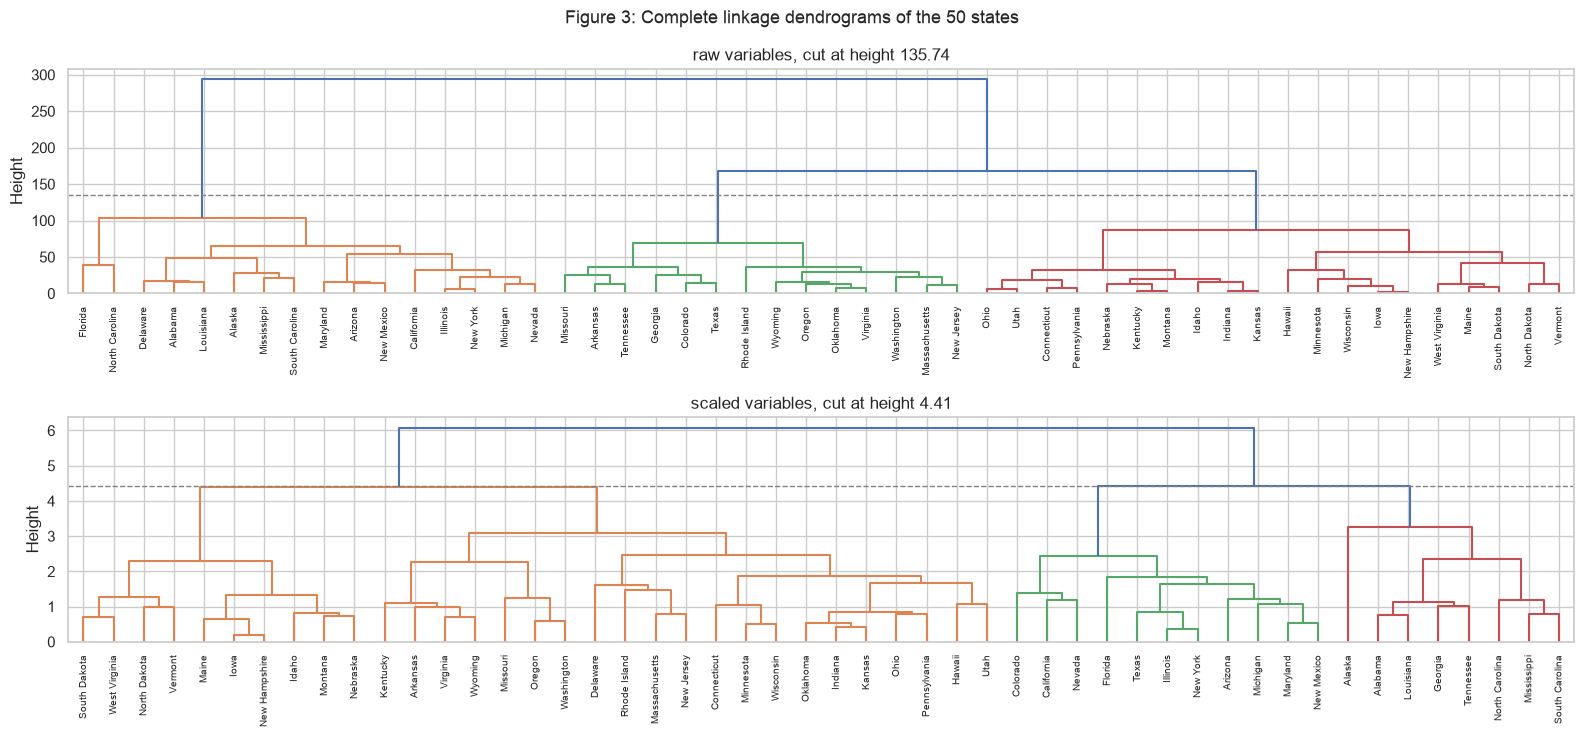

raw variables:
  cluster 1 (16 states): Alabama, Alaska, Arizona, California, Delaware,
    Florida, Illinois, Louisiana, Maryland, Michigan, Mississippi, Nevada,
    New Mexico, New York, North Carolina, South Carolina
  cluster 2 (14 states): Arkansas, Colorado, Georgia, Massachusetts,
    Missouri, New Jersey, Oklahoma, Oregon, Rhode Island, Tennessee, Texas,
    Virginia, Washington, Wyoming
  cluster 3 (20 states): Connecticut, Hawaii, Idaho, Indiana, Iowa, Kansas,
    Kentucky, Maine, Minnesota, Montana, Nebraska, New Hampshire, North
    Dakota, Ohio, Pennsylvania, South Dakota, Utah, Vermont, West Virginia,
    Wisconsin
  cluster means:
   Murder  Assault  UrbanPop  Rape
1    11.8    272.6      68.3  28.4
2     8.2    173.3      70.6  22.8
3     4.3     87.6      59.8  14.4
scaled variables:
  cluster 1 (31 states): Arkansas, Connecticut, Delaware, Hawaii, Idaho,
    Indiana, Iowa, Kansas, Kentucky, Maine, Massachusetts, Minnesota,
    Missouri, Montana, Nebraska, New Hampshir

In [8]:
# (a) and (c) complete linkage on the raw and the scaled variables
arrests_trees = {"raw": linkage(arrests_df.to_numpy(), method="complete"),
                 "scaled": linkage(arrests_df.to_numpy() / arrests_df.std().to_numpy(), method="complete")}
arrests_clusters = {}
fig, axes = plt.subplots(2, 1, figsize=(16, 7.5))
for ax, (name, tree) in zip(axes, arrests_trees.items()):
    # (b) cut halfway between the second and third highest fusions, which leaves three clusters
    cut = (tree[-3, 2] + tree[-2, 2]) / 2
    dendrogram(tree, labels=list(arrests_df.index), color_threshold=cut, leaf_font_size=7, ax=ax)
    ax.axhline(cut, color="gray", ls="--", lw=1)
    ax.set(title=f"{name} variables, cut at height {cut:.2f}", ylabel="Height")
    arrests_clusters[name] = fcluster(tree, t=3, criterion="maxclust")
fig.suptitle("Figure 3: Complete linkage dendrograms of the 50 states", fontsize=13)
plt.tight_layout()
plt.show()

for name, cluster_ids in arrests_clusters.items():
    print(f"{name} variables:")
    for c in np.unique(cluster_ids):
        states = f"cluster {c} ({(cluster_ids == c).sum()} states): " + ", ".join(arrests_df.index[cluster_ids == c])
        print(textwrap.fill(states, width=76, initial_indent="  ", subsequent_indent="    "))
    print("  cluster means:\n" + arrests_df.groupby(cluster_ids).mean().round(1).to_string())
print("\n" + pd.crosstab(pd.Series(arrests_clusters["raw"], name="raw cluster"), pd.Series(arrests_clusters["scaled"], name="scaled cluster")).to_string())
print("\nstandard deviation of each variable:", arrests_df.std().round(2).to_dict())

**Answer.**

- **(a)** Figure 3 (top) is the complete linkage dendrogram on the raw variables.
- **(b)** Cutting at height 135.74 gives three clusters of 16, 14 and 20 states, listed above. Cluster 1 has the highest crime rates (for example Florida, California, New York and the southern states), cluster 2 is in between, and cluster 3 has the lowest (for example the northern and midwestern states such as Iowa, Maine and North Dakota). Their mean Assault rates are 272.6, 173.3 and 87.6.
- **(c)** Figure 3 (bottom) is the same clustering after dividing each variable by its standard deviation. The three clusters now have 31, 11 and 8 states. Cluster 3 is eight states with high murder rates and a low urban population, all southern except Alaska (for example Georgia, Mississippi and the Carolinas), cluster 2 is eleven urban high-crime states (for example California, New York and Florida), and cluster 1 is the other 31.
- **(d)** Scaling changes the clusters a lot (the crosstab above). On the raw scale Assault has a standard deviation of 83.34 against 4.36 to 14.47 for the other variables, so the distances, and so the clusters, are almost only about Assault, as the cluster means show. After scaling all four variables count the same, and UrbanPop and Murder can split the high-crime states into urban states and southern states. **In my opinion the variables should be scaled here.** They are measured in different units (arrests per 100,000 people and percent urban population), and there is no reason for Assault to count more just because its numbers are larger.

## 4.9. ISLR 12.6.10 - Extra Practice

*Generate simulated data, and then perform PCA and K-means clustering on the data. (a) Generate a simulated data set with 20 observations in each of three classes (i.e. 60 observations total), and 50 variables, with a mean shift so that there are three distinct classes. (b) Perform PCA on the 60 observations and plot the first two principal component score vectors, with a different color for each class. If the three classes do not appear separated, modify the simulation until they do. (c) Perform K-means clustering of the observations with K = 3. How well do the clusters compare to the true class labels? (d) Perform K-means clustering with K = 2. Describe your results. (e) Now perform K-means clustering with K = 4, and describe your results. (f) Now perform K-means clustering with K = 3 on the first two principal component score vectors, rather than on the raw data. Comment on the results. (g) Perform K-means clustering with K = 3 on the data after scaling each variable to have standard deviation one. How do these results compare to those obtained in (b)? Explain.*

PVE of PC1 and PC2:

 [0.19  0.077]

(c) K = 3:
cluster   0   1   2
class              
A        18   2   0
B         0  20   0
C         0   0  20

(d) K = 2:
cluster   0   1
class          
A         1  19
B         0  20
C        20   0

(e) K = 4:
cluster   0   1   2   3
class                  
A         0   0  16   4
B        10   0   0  10
C         0  20   0   0

(f) K = 3 on the first two PC scores:
cluster   0   1   2
class              
A         0  18   2
B         0   0  20
C        20   0   0

(g) K = 3 after scaling:
cluster   0   1   2
class              
A         2  18   0
B        20   0   0
C         0   0  20

standard deviations of the 50 variables: min 0.86 max 1.35


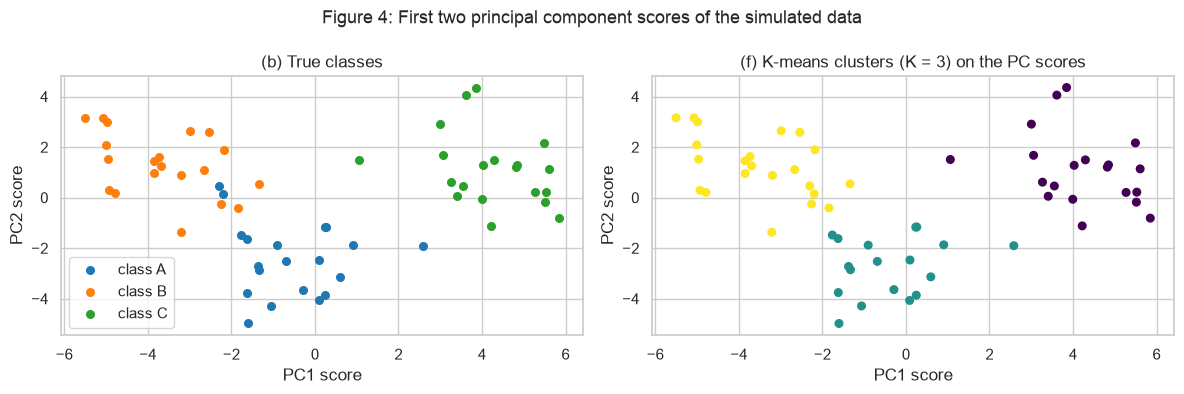

In [9]:
# (a) three classes of 20, class B is shifted up in the first 25 variables and class C in the last 25
rng = np.random.default_rng(SEED)
sim_X = rng.normal(size=(60, 50))
sim_class = np.repeat(["A", "B", "C"], 20)
sim_X[sim_class == "B", :25] += 1
sim_X[sim_class == "C", 25:] += 1

# (b) first two principal component score vectors
sim_pca = PCA(n_components=2).fit(sim_X)
sim_scores = sim_pca.transform(sim_X)
print("PVE of PC1 and PC2:", sim_pca.explained_variance_ratio_.round(3))

def kmeans_table(X, k):
    # true classes (rows) against the K-means clusters (columns)
    labels = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
    return pd.crosstab(pd.Series(sim_class, name="class"), pd.Series(labels, name="cluster")), labels

sim_runs = [("(c) K = 3", sim_X, 3), ("(d) K = 2", sim_X, 2), ("(e) K = 4", sim_X, 4),
            ("(f) K = 3 on the first two PC scores", sim_scores, 3), ("(g) K = 3 after scaling", StandardScaler().fit_transform(sim_X), 3)]
for title, X, k in sim_runs:
    table, _ = kmeans_table(X, k)
    print(f"\n{title}:\n{table.to_string()}")
print("\nstandard deviations of the 50 variables: min", sim_X.std(axis=0, ddof=1).min().round(2), "max", sim_X.std(axis=0, ddof=1).max().round(2))

_, pc_labels = kmeans_table(sim_scores, 3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for cls, color in zip(["A", "B", "C"], ["tab:blue", "tab:orange", "tab:green"]):
    axes[0].scatter(*sim_scores[sim_class == cls].T, c=color, label=f"class {cls}", s=30)
axes[0].set(xlabel="PC1 score", ylabel="PC2 score", title="(b) True classes")
axes[1].scatter(*sim_scores.T, c=pc_labels, cmap="viridis", s=30)
axes[1].set(xlabel="PC1 score", ylabel="PC2 score", title="(f) K-means clusters (K = 3) on the PC scores")
axes[0].legend()
fig.suptitle("Figure 4: First two principal component scores of the simulated data", fontsize=13)
plt.tight_layout()
plt.show()

**Answer.**

- **(a)** Class A has mean 0 in every variable, class B is shifted up by 1 in the first 25 variables and class C by 1 in the last 25.
- **(b)** The three classes are clearly separated in the first two principal component scores (Figure 4, left), even though PC1 and PC2 explain only 19.0% and 7.7% of the variance. Class A lies between B and C.
- **(c)** K-means with $K = 3$ gets 58 of the 60 observations right. Two class A observations go into the cluster of class B. The cluster numbers are arbitrary, so the table is read by matching each cluster to the class that fills it.
- **(d)** With $K = 2$ class C stays one cluster, and classes A and B are merged into the other (one A observation goes with C). A lies between B and C, so it is merged with one of its neighbours.
- **(e)** With $K = 4$ class C still stays whole. The extra cluster is built from parts of A and B (4 A and 10 B observations), so a cluster is split that should not be.
- **(f)** K-means on just the two PC score vectors gives the same 58 of 60 (Figure 4, right). The mean shifts lie along the first two components, so dropping the other 48 directions mostly drops noise.
- **(g)** After scaling each variable to standard deviation one the result is again 58 of 60. The simulated variables already have standard deviations between 0.86 and 1.35, so scaling changes almost nothing, and the classes stay as separated as in (b).

## 4.10. ISLR 12.6.11 - Extra Practice

*Write a function to perform matrix completion as in Algorithm 12.1, and as outlined in Section 12.5.2. In each iteration, the function should keep track of the relative error, as well as the iteration count. Iterations should continue until the relative error is small enough or until some maximum number of iterations is reached (set a default value for this maximum number). Furthermore, there should be an option to print out the progress in each iteration. Test your function on the `Boston` data. First, standardize the features to have mean zero and standard deviation one. Run an experiment where you randomly leave out an increasing (and nested) number of observations from 5% to 30%, in steps of 5%. Apply Algorithm 12.1 with $M = 1, 2, \dots, 8$. Display the approximation error as a function of the fraction of observations that are missing, and the value of $M$, averaged over 10 repetitions of the experiment.*

As in the lab, the relative error after each iteration is $(\text{MSS}_\text{old} - \text{MSS})/\text{MSS}_0$, where MSS is the mean squared error of the fit on the observed entries and $\text{MSS}_0$ the mean of the squared observed entries. The function stops when it falls below $10^{-7}$ or after `max_iter = 1000` iterations. The approximation error is the mean squared error between the imputed and the true (standardized) values of the left-out entries. In each repetition one random order of all $506 \times 13$ entries is drawn, and the first 5%, 10%, ... of that order are left out, so the missing sets are nested.

In [10]:
boston_df = pd.read_csv(BOSTON_PATH)
boston_X = StandardScaler().fit_transform(boston_df)
print(boston_df.shape, list(boston_df.columns))

def fit_svd(X, M):
    # best rank-M approximation from the first M singular vectors
    U, d, Vt = np.linalg.svd(X, full_matrices=False)
    return U[:, :M] * d[:M] @ Vt[:M]

def complete_matrix(X_na, M, fit=fit_svd, thresh=1e-7, max_iter=1000, verbose=False):
    # Algorithm 12.1, missing entries are NaN
    missing = np.isnan(X_na)
    col_means = np.nanmean(X_na, axis=0)
    X_hat = np.where(missing, col_means, X_na)
    mss0 = np.mean(X_na[~missing] ** 2)
    mss_old = np.mean((X_na - col_means)[~missing] ** 2)
    rel_err, n_iter = 1.0, 0
    while rel_err > thresh and n_iter < max_iter:
        n_iter += 1
        X_app = fit(X_hat, M)
        X_hat[missing] = X_app[missing]
        mss = np.mean((X_na - X_app)[~missing] ** 2)
        rel_err = (mss_old - mss) / mss0
        mss_old = mss
        if verbose:
            print(f"iter {n_iter}: MSS = {mss:.4f}, rel. err = {rel_err:.3e}")
    return X_hat, n_iter

def leave_out(X, order, fraction):
    # set the first fraction of the entries in order to NaN
    X_na = X.copy().ravel()
    X_na[order[:int(round(fraction * X.size))]] = np.nan
    return X_na.reshape(X.shape)

# one example run with the progress printed, 20% missing and M = 1
example_na = leave_out(boston_X, np.random.default_rng(0).permutation(boston_X.size), 0.2)
example_hat, _ = complete_matrix(example_na, M=1, verbose=True)
example_missing = np.isnan(example_na)
print(f"error on the missing entries = {np.mean((example_hat[example_missing] - boston_X[example_missing]) ** 2):.4f}")

(506, 13) ['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv']
iter 1: MSS = 0.5340, rel. err = 4.706e-01
iter 2: MSS = 0.5135, rel. err = 2.026e-02
iter 3: MSS = 0.5116, rel. err = 1.888e-03
iter 4: MSS = 0.5113, rel. err = 2.514e-04
iter 5: MSS = 0.5113, rel. err = 4.194e-05
iter 6: MSS = 0.5113, rel. err = 8.088e-06
iter 7: MSS = 0.5113, rel. err = 1.717e-06
iter 8: MSS = 0.5113, rel. err = 3.892e-07
iter 9: MSS = 0.5113, rel. err = 9.252e-08
error on the missing entries = 0.5787


Average error on the missing entries (10 repetitions), rows = fraction missing:
      M = 1  M = 2  M = 3  M = 4  M = 5  M = 6  M = 7  M = 8  column means
0.05  0.605  0.565  0.519  3.662  3.823  4.483  4.001  4.818         1.024
0.10  0.615  0.581  0.542  2.539  4.315  4.243  4.424  5.820         1.028
0.15  0.620  0.592  0.571  3.421  3.914  4.348  4.465  5.366         1.028
0.20  0.622  0.611  0.608  3.168  3.992  4.902  5.293  5.678         1.022
0.25  0.616  0.613  0.664  2.936  4.148  5.099  5.307  5.936         1.010
0.30  0.637  0.648  0.768  3.096  4.102  4.940  5.115  5.279         1.018

runs stopped at max_iter (of 60 for each M): {1: 0, 2: 0, 3: 0, 4: 23, 5: 31, 6: 41, 7: 46, 8: 50}
20% missing, M = 6, max_iter = 100: iterations = 100, error = 1.707
20% missing, M = 6, max_iter = 1000: iterations = 1000, error = 5.357


20% missing, M = 6, max_iter = 5000: iterations = 1612, error = 6.771


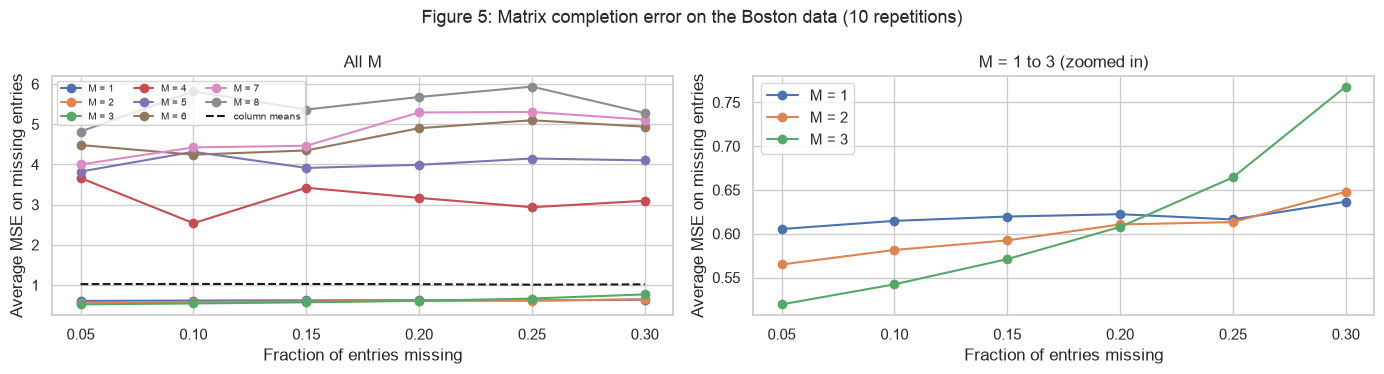

In [11]:
FRACTIONS = np.round(np.arange(0.05, 0.301, 0.05), 2)
M_VALUES = range(1, 9)

errors = np.zeros((10, len(FRACTIONS), len(M_VALUES)))
mean_errors = np.zeros((10, len(FRACTIONS)))
hit_cap = np.zeros(len(M_VALUES), dtype=int)
for rep in range(10):
    order = np.random.default_rng(rep).permutation(boston_X.size)
    for f, fraction in enumerate(FRACTIONS):
        X_na = leave_out(boston_X, order, fraction)
        missing = np.isnan(X_na)
        # filling with the column means, for reference
        mean_errors[rep, f] = np.mean((np.nanmean(X_na, axis=0)[np.where(missing)[1]] - boston_X[missing]) ** 2)
        for m, M in enumerate(M_VALUES):
            X_hat, n_iter = complete_matrix(X_na, M)
            errors[rep, f, m] = np.mean((X_hat[missing] - boston_X[missing]) ** 2)
            hit_cap[m] += n_iter == 1000

error_df = pd.DataFrame(errors.mean(axis=0), index=FRACTIONS, columns=[f"M = {M}" for M in M_VALUES])
error_df["column means"] = mean_errors.mean(axis=0)
print("Average error on the missing entries (10 repetitions), rows = fraction missing:\n" + error_df.round(3).to_string())
print("\nruns stopped at max_iter (of 60 for each M):", {M: int(count) for M, count in zip(M_VALUES, hit_cap)})

# what happens to one high-rank run if it is allowed more iterations
for cap in [100, 1000, 5000]:
    capped_hat, n_iter = complete_matrix(example_na, M=6, max_iter=cap)
    print(f"20% missing, M = 6, max_iter = {cap}: iterations = {n_iter}, error = {np.mean((capped_hat[example_missing] - boston_X[example_missing]) ** 2):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for m, M in enumerate(M_VALUES):
    axes[0].plot(FRACTIONS, errors.mean(axis=0)[:, m], marker="o", label=f"M = {M}")
axes[0].plot(FRACTIONS, mean_errors.mean(axis=0), "k--", label="column means")
axes[0].set(xlabel="Fraction of entries missing", ylabel="Average MSE on missing entries", title="All M")
axes[0].legend(fontsize=7, ncol=3)
for m in range(3):
    axes[1].plot(FRACTIONS, errors.mean(axis=0)[:, m], marker="o", label=f"M = {m + 1}")
axes[1].set(xlabel="Fraction of entries missing", ylabel="Average MSE on missing entries", title="M = 1 to 3 (zoomed in)")
axes[1].legend()
fig.suptitle("Figure 5: Matrix completion error on the Boston data (10 repetitions)", fontsize=13)
plt.tight_layout()
plt.show()

**Answer.** The table and Figure 5 show the average error on the left-out entries. The example run above needs 9 iterations with $M = 1$.

- **$M = 1$ to 3 work well.** Their errors are between 0.52 and 0.77, well below the 1.02 of filling in the column means. $M = 3$ is best when up to 20% is missing (0.519 at 5%), and $M = 1$ or 2 is best at 25 to 30% (0.637 for $M = 1$ at 30%). The errors grow as more entries are missing, fastest for $M = 3$, since there are fewer observed values to estimate more components from.
- **$M \ge 4$ is much worse than the column means** (errors from 2.5 to 5.9). With 13 variables a fit of rank 4 or more is flexible enough to keep improving on the observed entries while the missing ones are not pinned down, so they drift. Many of these runs stop at the 1000 iteration limit (23 of 60 for $M = 4$ up to 50 of 60 for $M = 8$), and letting them run longer makes them worse. In the $M = 6$ example the error is 1.707 after 100 iterations, 5.357 after 1000 and 6.771 when it finally stops after 1612.

So a small $M$ (1 to 3) should be used here. A larger $M$ would need early stopping or a penalty, as in soft-impute (Mazumder et al., 2010).

## 4.11. ISLR 12.6.12 - Extra Practice

*In Section 12.5.2, Algorithm 12.1 was implemented using the `svd()` function. However, given the connection between the `svd()` function and the `prcomp()` function highlighted in the lab, we could have instead implemented the algorithm using `prcomp()`. Write a function to implement Algorithm 12.1 that makes use of `prcomp()` rather than `svd()`.*

In Python, `PCA` plays the role of `prcomp()`. The rank-$M$ fit is the PCA reconstruction $\bar x + Z_M \Phi_M^T$ (scores times loadings, plus the column means that `PCA` removes), and it is passed to the same `complete_matrix` function.

In [12]:
def fit_pca(X, M):
    # rank-M fit from PCA: scores times loadings, plus the column means
    pca = PCA(n_components=M)
    return pca.inverse_transform(pca.fit_transform(X))

# same 20% missing example as in 4.10, svd version vs PCA version
for M in [1, 2, 3]:
    svd_hat, svd_iter = complete_matrix(example_na, M)
    pca_hat, pca_iter = complete_matrix(example_na, M, fit=fit_pca)
    print(f"M = {M}: svd error = {np.mean((svd_hat[example_missing] - boston_X[example_missing]) ** 2):.4f} ({svd_iter} iterations), "
          f"PCA error = {np.mean((pca_hat[example_missing] - boston_X[example_missing]) ** 2):.4f} ({pca_iter} iterations)")
    print(f"       largest difference in the imputed values = {np.abs(svd_hat - pca_hat).max():.4f}")

M = 1: svd error = 0.5787 (9 iterations), PCA error = 0.5840 (10 iterations)
       largest difference in the imputed values = 0.0694
M = 2: svd error = 0.6024 (16 iterations), PCA error = 0.6060 (16 iterations)
       largest difference in the imputed values = 0.0670
M = 3: svd error = 0.5790 (38 iterations), PCA error = 0.5812 (37 iterations)
       largest difference in the imputed values = 0.0892


**Answer.** The PCA version gives almost the same imputations as the svd version. On the same 20% missing example the errors are 0.5787 against 0.5840 ($M = 1$), 0.6024 against 0.6060 ($M = 2$) and 0.5790 against 0.5812 ($M = 3$), with about the same number of iterations, and no imputed value differs by more than 0.09. The small difference is that `PCA` (like `prcomp()`) centers the columns again before every fit and adds the means back, while the svd version fits a rank-$M$ approximation with no column means. The data are standardized, so the means are close to 0 and the two versions stay close.

## 4.12. ISLR 12.6.13 - Extra Practice

*On the book website, there is a gene expression data set (`Ch12Ex13.csv`) that consists of 40 tissue samples with measurements on 1,000 genes. The first 20 samples are from healthy patients, while the second 20 are from a diseased group. (a) Load in the data. (b) Apply hierarchical clustering to the samples using correlation-based distance, and plot the dendrogram. Do the genes separate the samples into the two groups? Do your results depend on the type of linkage used? (c) Your collaborator wants to know which genes differ the most across the two groups. Suggest a way to answer this question, and apply it here.*

(1000, 40)
complete linkage, two clusters (rows = true group):
cluster    1   2
group           
diseased  20   0
healthy   10  10
the diseased samples are a cluster of their own from 4 clusters on

average linkage, two clusters (rows = true group):
cluster    1  2
group          
diseased  20  0
healthy   11  9
the diseased samples are a cluster of their own from 8 clusters on

single linkage, two clusters (rows = true group):
cluster    1  2
group          
diseased  20  0
healthy   19  1
the diseased samples are a cluster of their own from 19 clusters on



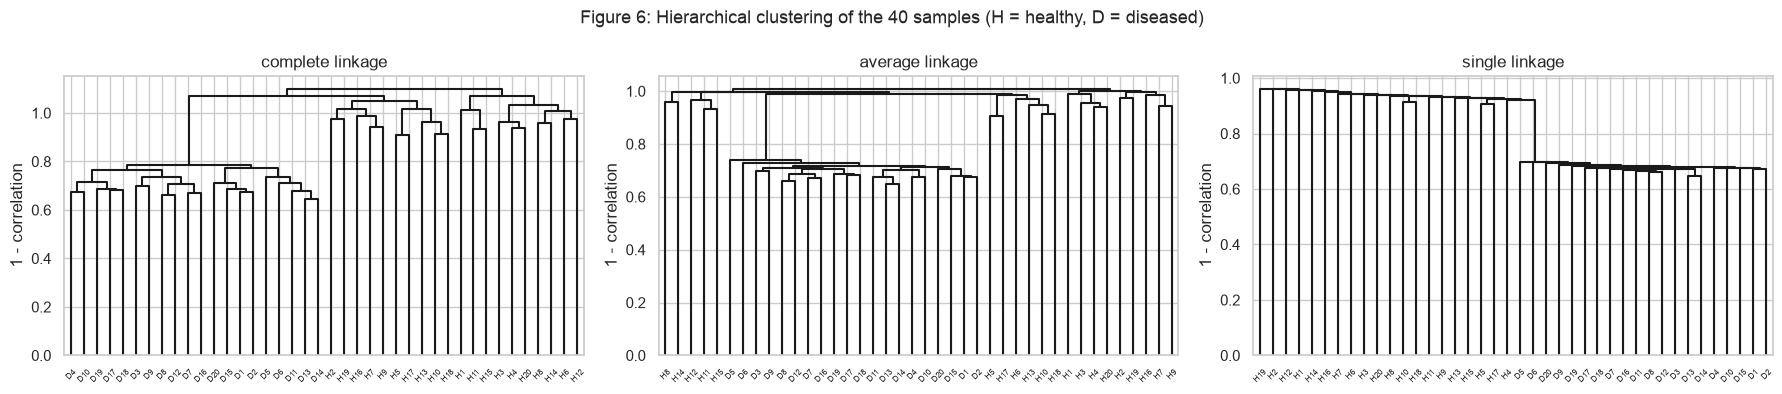

average correlation: diseased-diseased 0.286, healthy-healthy -0.002, healthy-diseased 0.002


In [13]:
# (a) no header row: 1000 genes (rows) by 40 samples (columns)
genes_df = pd.read_csv(GENES_PATH, header=None)
samples = genes_df.T.to_numpy()
sample_names = [f"H{i}" for i in range(1, 21)] + [f"D{i}" for i in range(1, 21)]
groups = np.repeat(["healthy", "diseased"], 20)
print(genes_df.shape)

# (b) correlation-based distance 1 - r between samples, three linkages
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, method in zip(axes, ["complete", "average", "single"]):
    tree = linkage(samples, method=method, metric="correlation")
    dendrogram(tree, labels=sample_names, leaf_font_size=6, color_threshold=0, above_threshold_color="k", ax=ax)
    ax.set(title=f"{method} linkage", ylabel="1 - correlation")
    two_clusters = fcluster(tree, t=2, criterion="maxclust")
    print(f"{method} linkage, two clusters (rows = true group):\n" + pd.crosstab(pd.Series(groups, name="group"), pd.Series(two_clusters, name="cluster")).to_string())
    # smallest number of clusters where the 20 diseased samples form a cluster of their own
    for k in range(2, 41):
        cluster_ids = fcluster(tree, t=k, criterion="maxclust")
        diseased_ids = set(cluster_ids[groups == "diseased"])
        if len(diseased_ids) == 1 and not diseased_ids & set(cluster_ids[groups == "healthy"]):
            print(f"the diseased samples are a cluster of their own from {k} clusters on\n")
            break
fig.suptitle("Figure 6: Hierarchical clustering of the 40 samples (H = healthy, D = diseased)", fontsize=13)
plt.tight_layout()
plt.show()

# average correlation between samples, within and across the groups
sample_corr = np.corrcoef(samples)
upper = np.triu_indices(20, k=1)
print(f"average correlation: diseased-diseased {sample_corr[20:, 20:][upper].mean():.3f}, healthy-healthy {sample_corr[:20, :20][upper].mean():.3f}, healthy-diseased {sample_corr[:20, 20:].mean():.3f}")

**Answer.** The diseased samples are correlated with each other (average $r = 0.286$), while the healthy samples are not correlated with each other or with the diseased ones (average $r$ about 0). So in every linkage the 20 diseased samples join early (at $1 - r$ of about 0.65 to 0.8), and the healthy samples join late, near 1 (Figure 6).

**The genes separate out the diseased group, but a cut into two clusters does not give the two groups.** With two clusters complete linkage puts the 20 diseased and 10 healthy samples together, average linkage 20 diseased and 11 healthy, and single linkage everything except one healthy sample. The diseased samples become a cluster of their own at 4 clusters with complete linkage, 8 with average linkage and 19 with single linkage. **So the result depends on the linkage.** Complete linkage comes closest, and single linkage is the worst because it chains the healthy samples on one at a time. The healthy samples look like pure noise, so they do not form a group of their own.

genes with p < 0.05: 159, significant after the Bonferroni correction (p < 0.05/1000): 105
significant genes in 11-20: 10, in 501-600: 95, elsewhere: 0
mean difference (diseased - healthy) of the significant genes: 1.45 to 2.75

10 genes with the smallest p-values:
 gene       t  p-value  mean difference
  502 10.3167 1.43e-12           2.5445
  589 10.0246 3.19e-12           2.3435
  600  9.6234 9.81e-12           2.7476
  590  8.9762 6.28e-11           2.2053
  565  8.6287 1.74e-10           2.4708
  551  8.0114 1.10e-09           2.3428
  593  7.9843 1.19e-09           2.4021
  584  7.8771 1.65e-09           2.6020
  538  7.7516 2.42e-09           2.3920
  569  7.7174 2.69e-09           1.9762

10 genes with the largest |PC1 loading|: [600 584 549 540 502 582 565 568 529 599]


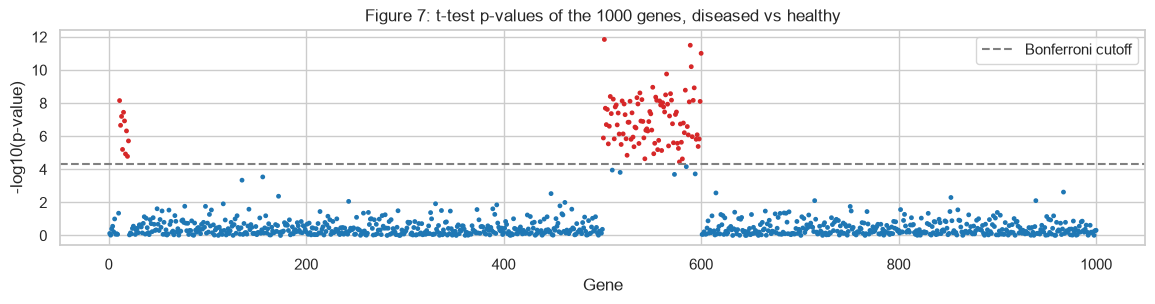

In [14]:
# (c) two-sample t-test for each gene, healthy vs diseased
t_stats, p_values = ttest_ind(samples[groups == "diseased"], samples[groups == "healthy"], axis=0)
mean_diff = samples[groups == "diseased"].mean(axis=0) - samples[groups == "healthy"].mean(axis=0)
significant = np.where(p_values < 0.05 / 1000)[0]
print(f"genes with p < 0.05: {(p_values < 0.05).sum()}, significant after the Bonferroni correction (p < 0.05/1000): {len(significant)}")
in_11_20 = np.isin(significant + 1, range(11, 21)).sum()
in_501_600 = np.isin(significant + 1, range(501, 601)).sum()
print(f"significant genes in 11-20: {in_11_20}, in 501-600: {in_501_600}, elsewhere: {len(significant) - in_11_20 - in_501_600}")
print(f"mean difference (diseased - healthy) of the significant genes: {mean_diff[significant].min():.2f} to {mean_diff[significant].max():.2f}")

top_genes = pd.DataFrame({"gene": np.arange(1, 1001), "t": t_stats, "p-value": p_values, "mean difference": mean_diff}).sort_values("p-value").head(10)
print("\n10 genes with the smallest p-values:\n" + top_genes.to_string(index=False, formatters={"p-value": "{:.2e}".format}))

# another way: the genes with the largest loadings on the first principal component of the samples
pc1_loadings = PCA(n_components=1).fit(samples).components_[0]
print("\n10 genes with the largest |PC1 loading|:", np.argsort(-np.abs(pc1_loadings))[:10] + 1)

plt.figure(figsize=(14, 2.8))
plt.scatter(np.arange(1, 1001), -np.log10(p_values), s=6, c=np.where(p_values < 0.05 / 1000, "tab:red", "tab:blue"))
plt.axhline(-np.log10(0.05 / 1000), color="gray", ls="--", label="Bonferroni cutoff")
plt.xlabel("Gene")
plt.ylabel("-log10(p-value)")
plt.title("Figure 7: t-test p-values of the 1000 genes, diseased vs healthy")
plt.legend()
plt.show()

**Answer.** A simple way is a **two-sample t-test for every gene** (diseased against healthy), with a correction for testing 1000 genes at once. With the Bonferroni correction (p below 0.05/1000) **105 genes are significant**, 10 of genes 11 to 20 and 95 of genes 501 to 600, and no others (Figure 7). All of them are higher in the diseased group, by 1.45 to 2.75 on average. The 10 genes with the smallest p-values are listed above, led by gene 502 ($t = 10.3$, $p = 1.4 \times 10^{-12}$). Another option is to rank the genes by their loadings on the first principal component of the samples, which picks out the same block of genes, or to control the false discovery rate instead of using Bonferroni if a longer list is acceptable.

### References

1. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (ISLR), 2nd ed., Ch. 12.2 (principal components and the proportion of variance explained), Ch. 12.3 (matrix completion, Algorithm 12.1), Ch. 12.4 (K-means and hierarchical clustering) and Ch. 12.5 (lab).
2. ISLR data sets: `USArrests` (R `datasets` package, via https://vincentarelbundock.github.io/Rdatasets/), `Boston` (ISLR2 version, https://github.com/intro-stat-learning/ISLP) and `Ch12Ex13.csv` (https://www.statlearning.com).
3. R. Mazumder, T. Hastie, R. Tibshirani, "Spectral regularization algorithms for learning large incomplete matrices," *Journal of Machine Learning Research*, 11 (2010), 2287-2322.